<a href="https://colab.research.google.com/github/filarancesonia/filarancesonia/blob/main/Soniya_Filarance_M_Day5_Validating_tuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Libraries imported successfully!
Dataset loaded successfully!
Dataset shape: (569, 30)
Target shape: (569,)
Feature names: ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']
Target names: ['malignant' 'benign']
Training data: (398, 30)
Validation data: (85, 30)
Testing data: (86, 30)
Baseline Accuracy: 0.976
Fold Scores: [0.962 0.912 0.938 0.987 0.962]
Mean Accuracy: 0.952
Pipeline Fold Scores: [1.    0.975 0.988 1.    0.949]
Pipeline Mean Accuracy: 0.982
Best Parameters: {'model__C': 0.1}
B

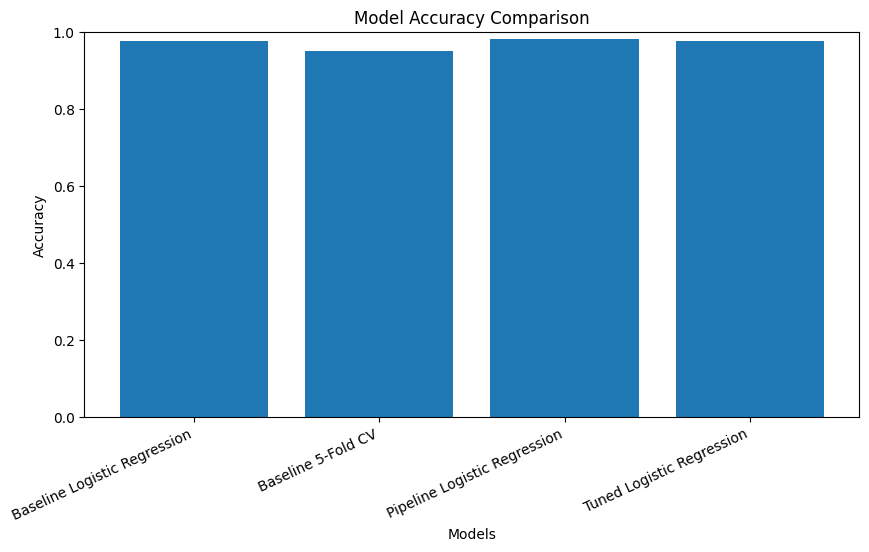

In [2]:
!pip install -q scikit-learn pandas matplotlib seaborn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV

print("Libraries imported successfully!")
data = load_breast_cancer()

X = data.data
y = data.target

print("Dataset loaded successfully!")
print("Dataset shape:", X.shape)
print("Target shape:", y.shape)
print("Feature names:", data.feature_names)
print("Target names:", data.target_names)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50,
    random_state=42, stratify=y_temp
)

print("Training data:", X_train.shape)
print("Validation data:", X_valid.shape)
print("Testing data:", X_test.shape)
model = LogisticRegression(max_iter=10000)

model.fit(X_train, y_train)

y_pred = model.predict(X_valid)

baseline_accuracy = accuracy_score(y_valid, y_pred)

print("Baseline Accuracy:", round(baseline_accuracy, 3))
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Fold Scores:", scores.round(3))
print("Mean Accuracy:", round(scores.mean(), 3))
pipe = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=10000))
])

pipe_scores = cross_val_score(
    pipe,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Pipeline Fold Scores:", pipe_scores.round(3))
print("Pipeline Mean Accuracy:", round(pipe_scores.mean(), 3))
grid = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

search = GridSearchCV(
    pipe,
    grid,
    cv=cv,
    scoring="accuracy"
)

search.fit(X_train, y_train)

print("Best Parameters:", search.best_params_)
print("Best CV Accuracy:", round(search.best_score_, 3))
best_model = search.best_estimator_

y_test_pred = best_model.predict(X_test)

tuned_accuracy = accuracy_score(y_test, y_test_pred)

print("Tuned Model Test Accuracy:", round(tuned_accuracy, 3))
results = pd.DataFrame({
    "Model": [
        "Baseline Logistic Regression",
        "Baseline 5-Fold CV",
        "Pipeline Logistic Regression",
        "Tuned Logistic Regression"
    ],
    "Accuracy": [
        baseline_accuracy,
        scores.mean(),
        pipe_scores.mean(),
        tuned_accuracy
    ]
})

results["Accuracy"] = results["Accuracy"].round(3)

print(results)
plt.figure(figsize=(10, 5))

plt.bar(results["Model"], results["Accuracy"])

plt.title("Model Accuracy Comparison")
plt.xlabel("Models")
plt.ylabel("Accuracy")

plt.xticks(rotation=25, ha="right")
plt.ylim(0, 1)
plt.show()
